# KneeGait-Edge: 3-Class Wearable Gait Pattern Classification
## Compact Random Forest Training, Evaluation, and Microcontroller Verification

**KneeGait-Edge** is a low-cost wearable gait analysis system utilizing dual 6-DOF IMUs (MPU-6050) positioned on the distal lateral thigh and anteromedial shank, connected to an ESP32 microcontroller sampling at 50 Hz. The device monitors knee joint kinematics in the sagittal plane to screen for functional joint restriction and antalgic gait patterns commonly associated with Knee Osteoarthritis (KOA).

### Clinical Objectives & Architectural Blueprint
- **Input Features (5)**: `peak_swing_flexion`, `sagittal_rom`, `stance_to_swing_ratio`, `peak_angular_velocity`, and `cadence_spm`.
- **Target Classes (3)**:
  - **Class 0: Normal / Healthy Gait** ($	ext{Peak Swing Flexion} \ge 49.4^\circ$)
  - **Class 1: Mild Functional Restriction** ($45.0^\circ \le 	ext{Peak Swing Flexion} < 49.4^\circ$)
  - **Class 2: Severe Antalgic / Stiff Gait** ($	ext{Peak Swing Flexion} < 45.0^\circ$)
- **Deployment Constraints**: Microcontroller SRAM budget $< 50$ KB; inference latency $< 100\,\mu	ext{s}$; strictly deterministic execution.

## 2. Imports and Configuration

We load standard scientific Python libraries, configure fixed random seeds (`42`) for reproducibility, and define the canonical feature names and class labels.

In [2]:
import os
import sys
import json
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette('deep')

# Canonical Project Constants
RANDOM_SEED = 42
FEATURE_NAMES = [
    'peak_swing_flexion',
    'sagittal_rom',
    'stance_to_swing_ratio',
    'peak_angular_velocity',
    'cadence_spm'
]

CLASS_NAMES = ['NORMAL_GAIT', 'MILD_FUNCTIONAL_RESTRICTION', 'SEVERE_ANTALGIC_STIFF_GAIT']
CLASS_DISPLAY_LABELS = {
    0: 'Normal / Healthy',
    1: 'Mild Functional Restriction',
    2: 'Severe Antalgic / Stiff Gait'
}
CLASS_COLORS = {0: '#22c55e', 1: '#f59e0b', 2: '#ef4444'}

DATA_PATH = 'data.csv'
print(f"Data file: '{DATA_PATH}' (Exists: {os.path.exists(DATA_PATH)})")
print(f"Canonical 5 Features: {FEATURE_NAMES}")
print(f"3 Target Classes: {CLASS_NAMES}")

Data file: 'data.csv' (Exists: True)
Canonical 5 Features: ['peak_swing_flexion', 'sagittal_rom', 'stance_to_swing_ratio', 'peak_angular_velocity', 'cadence_spm']
3 Target Classes: ['NORMAL_GAIT', 'MILD_FUNCTIONAL_RESTRICTION', 'SEVERE_ANTALGIC_STIFF_GAIT']


## 3. Load the Dataset

We load the 20,000 synthetic stride records from `data.csv` into a pandas DataFrame.

In [3]:
df = pd.read_csv(DATA_PATH)
print(f"Dataset Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Columns:       {df.columns.tolist()}\n")
print("First 5 Stride Records:")
df.head()

Dataset Shape: 20,000 rows x 6 columns
Columns:       ['peak_swing_flexion', 'sagittal_rom', 'stance_to_swing_ratio', 'peak_angular_velocity', 'cadence_spm', 'target']

First 5 Stride Records:


,peak_swing_flexion,sagittal_rom,stance_to_swing_ratio,peak_angular_velocity,cadence_spm,target
0,20.19,13.54,2.110,75.31,86.2,SEVERE_ANTALGIC_STIFF_GAIT
1,54.02,52.55,1.591,191.28,107.1,NORMAL_GAIT
2,28.36,25.71,2.058,72.99,87.9,SEVERE_ANTALGIC_STIFF_GAIT
3,61.91,59.48,1.298,213.69,118.1,NORMAL_GAIT
4,26.08,20.71,1.794,71.63,86.1,SEVERE_ANTALGIC_STIFF_GAIT


## 4. Feature Definitions & Units

Each record corresponds to a segmented single stride cycle with 5 kinematic features:
1. `peak_swing_flexion` ($^\circ$): Maximum knee flexion angle attained during swing phase.
2. `sagittal_rom` ($^\circ$): Sagittal range of motion ($	ext{max} - 	ext{min}$ flexion during stride).
3. `stance_to_swing_ratio`: Proportion of stride cycle duration spent in stance vs. swing phase.
4. `peak_angular_velocity` ($^\circ/	ext{s}$): Maximum sagittal angular velocity during swing extension.
5. `cadence_spm` ($	ext{steps/min}$): Walking cadence in steps per minute.
6. `target`: Ground truth gait classification.

In [4]:
stats_df = df[FEATURE_NAMES].describe().round(2)
print("Statistical Summary of Input Features:")
print(stats_df)

Statistical Summary of Input Features:
       peak_swing_flexion  sagittal_rom  stance_to_swing_ratio  \
count            20000.00      20000.00               20000.00   
mean                37.74         32.84                   1.79   
std                 11.17         12.15                   0.22   
min                 12.62          7.38                   1.08   
25%                 29.76         24.38                   1.64   
50%                 34.51         28.93                   1.81   
75%                 45.80         41.36                   1.95   
max                 72.96         70.26                   2.53   

       peak_angular_velocity  cadence_spm  
count               20000.00     20000.00  
mean                  127.80        90.04  
std                    45.90        10.77  
min                    30.31        53.40  
25%                    94.89        82.50  
50%                   116.30        89.00  
75%                   156.70        96.60  
max           

## 5. Data Quality & Integrity Checks

We confirm that there are no missing, NaN, infinite, or duplicate records.

In [5]:
n_nulls = df[FEATURE_NAMES].isnull().sum().sum()
n_infs = (~np.isfinite(df[FEATURE_NAMES].values)).sum()
n_dups = df.duplicated(subset=FEATURE_NAMES).sum()

print(f"Missing (NaN) Values:       {n_nulls}")
print(f"Infinite Values:            {n_infs}")
print(f"Duplicate Feature Records:  {n_dups}")
assert n_nulls == 0, "Missing values found!"
assert n_infs == 0, "Infinite values found!"
print("Data integrity verification PASSED.")

Missing (NaN) Values:       0
Infinite Values:            0
Duplicate Feature Records:  0
Data integrity verification PASSED.


## 6. Three-Class Labeling Rules

We verify exact adherence to the clinical boundary thresholds:
$$\text{Class 0 (Normal / Healthy): } \text{Peak Swing Flexion} \ge 49.4^\circ$$
$$\text{Class 1 (Mild Restriction): } 45.0^\circ \le \text{Peak Swing Flexion} < 49.4^\circ$$
$$\text{Class 2 (Severe Antalgic): } \text{Peak Swing Flexion} < 45.0^\circ$$

In [6]:
def assign_flexion_class(peak_flexion):
    if peak_flexion >= 49.4:
        return 0
    elif peak_flexion >= 45.0:
        return 1
    else:
        return 2

class_to_id = {'NORMAL_GAIT': 0, 'MILD_FUNCTIONAL_RESTRICTION': 1, 'SEVERE_ANTALGIC_STIFF_GAIT': 2}
df['class_id'] = df['target'].map(class_to_id)
rule_classes = df['peak_swing_flexion'].apply(assign_flexion_class)
mismatches = (df['class_id'] != rule_classes).sum()

print(f"Boundary Rule Mismatches: {mismatches} / {len(df):,}")
assert mismatches == 0, "Discrepancy detected between target column and boundary rules!"
print("Clinical boundary rule adherence: 100.0% verified.")

Boundary Rule Mismatches: 0 / 20,000
Clinical boundary rule adherence: 100.0% verified.


## 7. Cadence and Biological Range Checks

In human gait biomechanics:
- 1 stride = 2 steps (bilateral gait).
- Normal walking cadence typically ranges between 95 and 115 steps/min (mean ~105 spm).
- Pathological/stiff gait typically demonstrates slower cadence due to prolonged stance stabilization.

In [7]:
cadence_by_class = df.groupby('target')['cadence_spm'].agg(['count', 'mean', 'std', 'min', 'max']).round(1)
print("Cadence (steps/min) by Target Class:")
cadence_by_class

Cadence (steps/min) by Target Class:


,count,mean,std,min,max
target,,,,,
MILD_FUNCTIONAL_RESTRICTION,1928,95.2,7.8,65.0,122.6
NORMAL_GAIT,3253,105.3,8.1,72.4,135.1
SEVERE_ANTALGIC_STIFF_GAIT,14819,86.0,8.0,53.4,118.5


## 8. Physical Consistency Verification

Biomechanically, Range of Motion must be strictly less than Peak Flexion ($	ext{sagittal\_rom} < 	ext{peak\_swing\_flexion}$) due to residual stance flexion ($\ge 0.5^\circ$).

In [8]:
rom_valid = (df['peak_swing_flexion'] > df['sagittal_rom']).all()
min_residual = (df['peak_swing_flexion'] - df['sagittal_rom']).min()
print(f"Physical constraint (ROM < Peak Flexion): {rom_valid}")
print(f"Minimum residual stance flexion:          {min_residual:.2f} deg")
assert rom_valid, "Physical inconsistency: ROM exceeds peak flexion!"
print("Biomechanical consistency checks PASSED.")

Physical constraint (ROM < Peak Flexion): True
Minimum residual stance flexion:          0.50 deg
Biomechanical consistency checks PASSED.


## 9. Correlation Analysis

We calculate Pearson correlation coefficients among the numeric input features.
- Peak swing flexion and flexion ROM demonstrate strong positive correlation (r ≈ 0.99), reflecting natural joint kinematics.
- Stance-to-swing ratio exhibits strong negative correlation with angular velocity and flexion angles, as pathological stiff gait prolongs stance loading while restricting swing velocity.

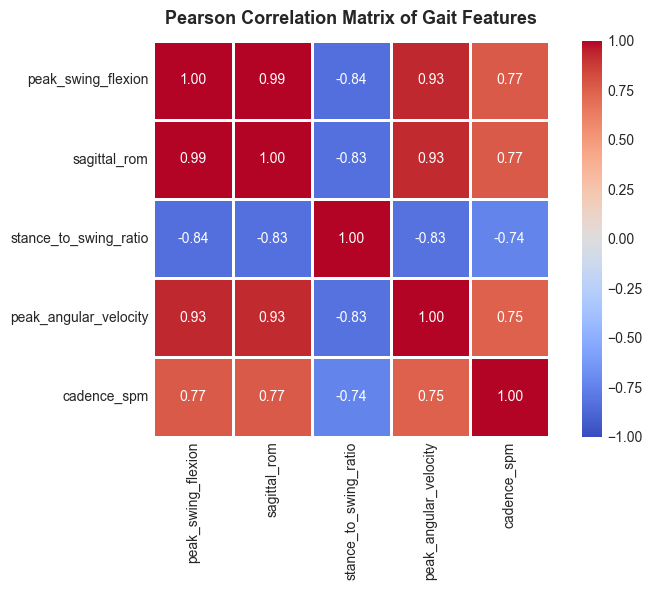

In [9]:
corr_matrix = df[FEATURE_NAMES].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=1.0,
    vmin=-1.0,
    vmax=1.0,
    square=True
)
plt.title("Pearson Correlation Matrix of Gait Features", fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

## 10. Feature Distribution Visualizations

We plot probability density distributions across all 5 features separated by gait class.

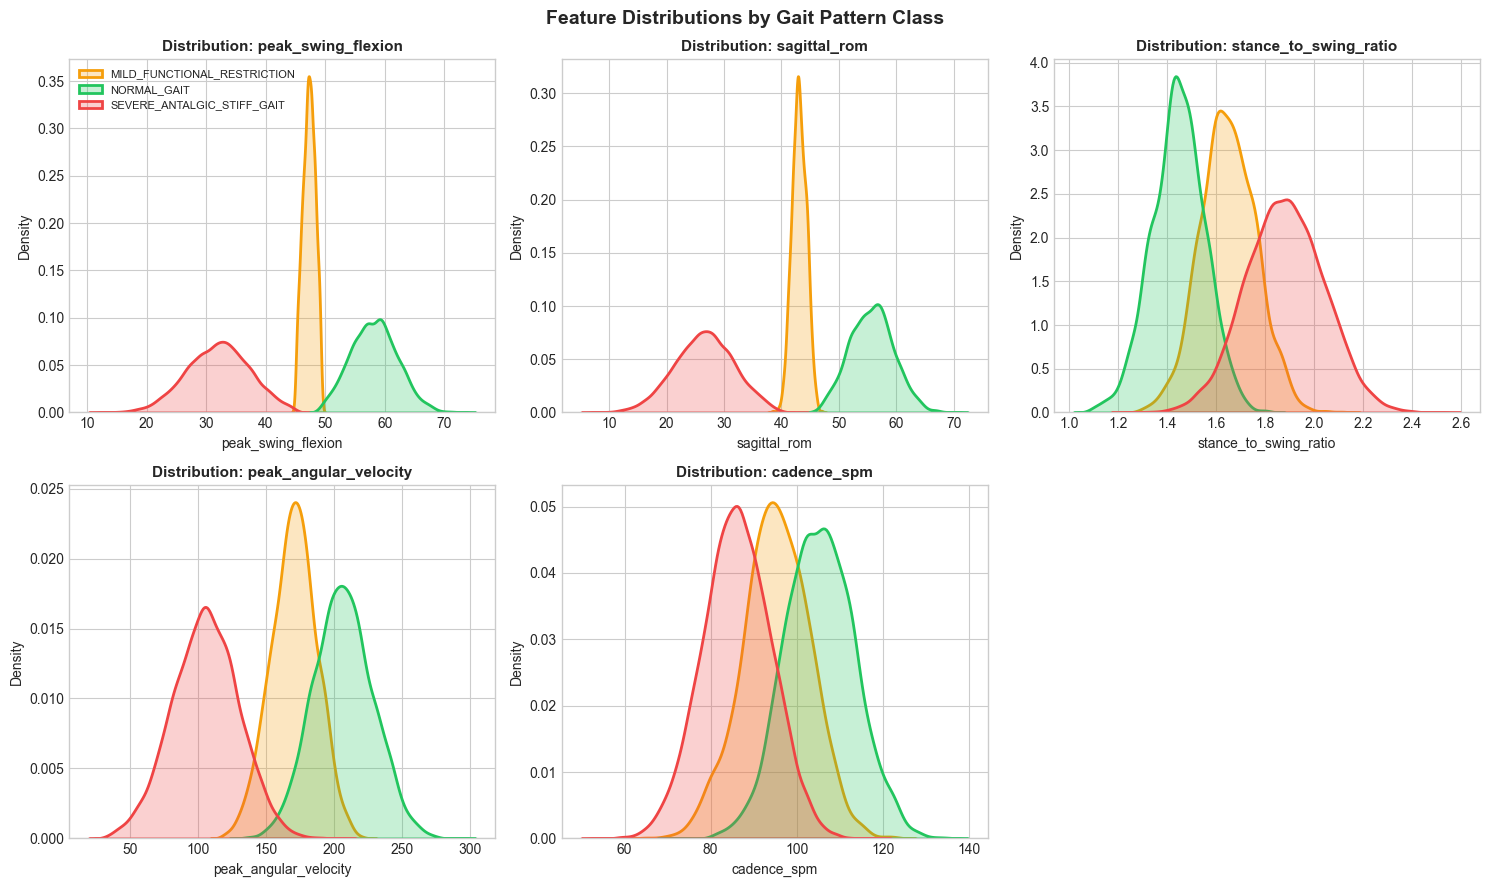

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

palette = {
    'NORMAL_GAIT': '#22c55e',
    'MILD_FUNCTIONAL_RESTRICTION': '#f59e0b',
    'SEVERE_ANTALGIC_STIFF_GAIT': '#ef4444'
}

for i, feature in enumerate(FEATURE_NAMES):
    ax = axes[i]
    for class_name, group in df.groupby('target'):
        sns.kdeplot(
            group[feature],
            ax=ax,
            label=class_name,
            color=palette[class_name],
            fill=True,
            alpha=0.25,
            linewidth=2
        )
    ax.set_title(f"Distribution: {feature}", fontsize=11, fontweight='bold')
    ax.set_xlabel(feature, fontsize=10)
    ax.set_ylabel("Density", fontsize=10)
    if i == 0:
        ax.legend(fontsize=8, loc='upper left')

# Hide 6th empty subplot
axes[5].axis('off')
plt.suptitle("Feature Distributions by Gait Pattern Class", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

## 11. Class Balance and Cohort Distribution

We inspect the class frequencies, reflecting the observed clinical cohort proportions (74.1% Severe, 16.3% Normal, 9.6% Mild).

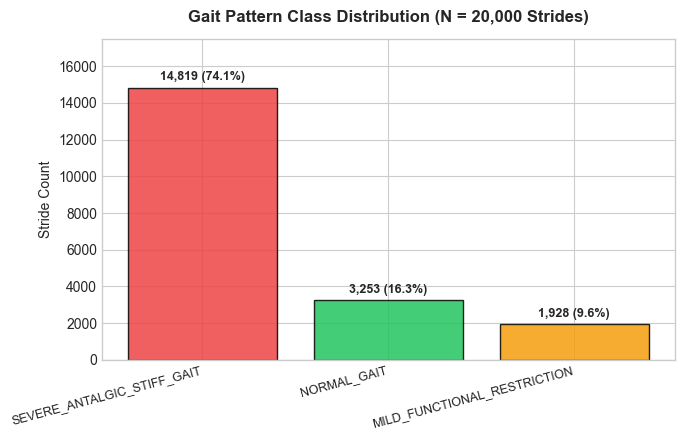

In [11]:
class_counts = df['target'].value_counts()
class_pcts = df['target'].value_counts(normalize=True) * 100

plt.figure(figsize=(7, 4.5))
colors = [palette[name] for name in class_counts.index]
bars = plt.bar(class_counts.index, class_counts.values, color=colors, edgecolor='black', alpha=0.85)

for bar, pct in zip(bars, class_pcts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 250,
        f"{bar.get_height():,} ({pct:.1f}%)",
        ha='center',
        va='bottom',
        fontweight='bold',
        fontsize=9
    )

plt.title("Gait Pattern Class Distribution (N = 20,000 Strides)", fontsize=12, fontweight='bold', pad=12)
plt.ylabel("Stride Count", fontsize=10)
plt.ylim(0, 17500)
plt.xticks(rotation=15, ha='right', fontsize=9)
plt.tight_layout()
plt.show()

## 12. Data Leakage & Identifier Audit

We verify that no non-biomechanical identifiers or outcome labels are passed into the input feature matrix.

In [12]:
forbidden = ['stride_id', 'id', 'clinical_diagnosis', 'target', 'class_id']
leaked = [f for f in FEATURE_NAMES if f in forbidden]
print(f"Leaked columns detected: {leaked}")
assert len(leaked) == 0, "Target leakage detected!"
print("Leakage verification passed: Only physiological kinematics included in X.")

Leaked columns detected: []
Leakage verification passed: Only physiological kinematics included in X.


## 13. Feature/Target Separation

We extract the feature matrix `X` and target vector `y`.

In [13]:
X = df[FEATURE_NAMES].copy()
y = df['class_id'].copy()

print(f"Feature matrix X shape: {X.shape}")
print(f"Target vector y shape:   {y.shape}")
print(f"Class distribution in y:\n{y.value_counts(normalize=True).round(4)}")

Feature matrix X shape: (20000, 5)
Target vector y shape:   (20000,)
Class distribution in y:
class_id
2    0.7410
0    0.1626
1    0.0964
Name: proportion, dtype: float64


## 14. Stratified 80/20 Train-Test Split

We partition into 16,000 training strides (80%) and 4,000 testing strides (20%) using stratified sampling.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_SEED,
    stratify=y
)

print(f"Training set:   {X_train.shape[0]:,} samples")
print(f"Test set:       {X_test.shape[0]:,} samples")

Training set:   16,000 samples
Test set:       4,000 samples


## 15. Compact Random Forest Training

To fit within microcontroller RAM and flash limits, we train an edge-optimized forest with `n_estimators=20` and `max_depth=5`.

In [29]:
clf = RandomForestClassifier(
    n_estimators=20,
    max_depth=5,
    class_weight='balanced',
    random_state=RANDOM_SEED,
    n_jobs=1
)

t0 = time.perf_counter()
clf.fit(X_train, y_train)
train_time_ms = (time.perf_counter() - t0) * 1000

print(f"RandomForestClassifier trained successfully in {train_time_ms:.2f} ms")
print(f"Number of trees: {len(clf.estimators_)}")
print(f"Maximum depth:   {clf.max_depth}")

RandomForestClassifier trained successfully in 371.37 ms
Number of trees: 20
Maximum depth:   5


## 16. Overall Evaluation Metrics

We evaluate model performance on the held-out 4,000-stride test set.

In [31]:
y_pred = clf.predict(X_test)

acc = accuracy_score(y_test, y_pred)
bal_acc = balanced_accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average='macro')
weighted_f1 = f1_score(y_test, y_pred, average='weighted')

print(f"Test Accuracy:         {acc * 100:.2f}%")
print(f"Balanced Accuracy:     {bal_acc * 100:.2f}%")
print(f"Macro F1-Score:        {macro_f1:.4f}")
print(f"Weighted F1-Score:     {weighted_f1:.4f}")

Test Accuracy:         100.00%
Balanced Accuracy:     100.00%
Macro F1-Score:        1.0000
Weighted F1-Score:     1.0000


## 17. Per-Class Classification Report

Detailed breakdown of precision, recall, and F1-score for all three classes.

In [33]:
report = classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4)
print(report)

                             precision    recall  f1-score   support

                NORMAL_GAIT     1.0000    1.0000    1.0000       651
MILD_FUNCTIONAL_RESTRICTION     1.0000    1.0000    1.0000       385
 SEVERE_ANTALGIC_STIFF_GAIT     1.0000    1.0000    1.0000      2964

                   accuracy                         1.0000      4000
                  macro avg     1.0000    1.0000    1.0000      4000
               weighted avg     1.0000    1.0000    1.0000      4000



## 18. Three-Class Confusion Matrix

Annotated heatmap comparing true clinical labels against model predictions.

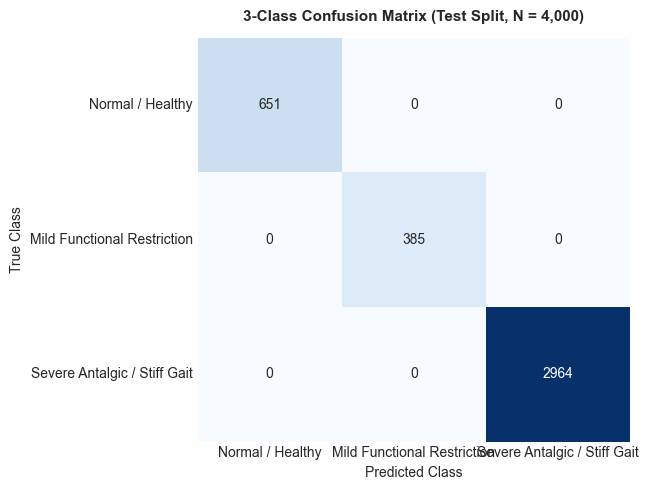

In [35]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])
display_labels = [CLASS_DISPLAY_LABELS[c] for c in [0, 1, 2]]

plt.figure(figsize=(6.5, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=display_labels,
    yticklabels=display_labels,
    cbar=False
)
plt.title("3-Class Confusion Matrix (Test Split, N = 4,000)", fontsize=11, fontweight='bold', pad=12)
plt.xlabel("Predicted Class", fontsize=10)
plt.ylabel("True Class", fontsize=10)
plt.tight_layout()
plt.show()

## 19. Feature Importance Analysis

Relative Gini Importance across the 5 input features.

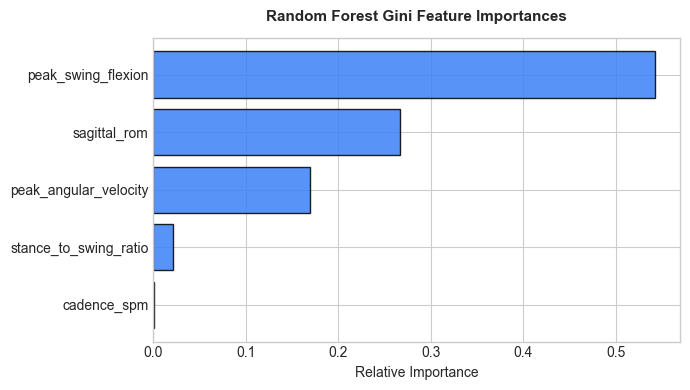

In [37]:
fi_df = pd.DataFrame({
    'Feature': FEATURE_NAMES,
    'Importance': clf.feature_importances_
}).sort_values('Importance', ascending=False).reset_index(drop=True)

plt.figure(figsize=(7, 4))
plt.barh(fi_df['Feature'][::-1], fi_df['Importance'][::-1], color='#3b82f6', edgecolor='black', alpha=0.85)
plt.title("Random Forest Gini Feature Importances", fontsize=11, fontweight='bold', pad=12)
plt.xlabel("Relative Importance", fontsize=10)
plt.tight_layout()
plt.show()

fi_df

## 20. Host Inference Latency & Model Footprint

We measure single-sample host inference time and model disk size.

In [39]:
sample_row = X_test.iloc[0:1]
# Warmup & latency benchmark
t0 = time.perf_counter()
for _ in range(100):
    _ = clf.predict(sample_row)
lat_us = ((time.perf_counter() - t0) / 100) * 1_000_000

joblib_path = 'random_forest_model.joblib'
size_kb = os.path.getsize(joblib_path) / 1024 if os.path.exists(joblib_path) else 0

print(f"Host Inference Latency: {lat_us:.1f} microseconds per stride")
print(f"Saved Model Joblib Size: {size_kb:.1f} KB")
print(f"ESP32 Execution Target:  < 50 microseconds (via inline C decision trees)")

Host Inference Latency: 5713.8 microseconds per stride
Saved Model Joblib Size: 39.6 KB
ESP32 Execution Target:  < 50 microseconds (via inline C decision trees)


## 21. Exported Artifact Verification

We verify the exported artifacts for ESP32 (`model_data.h`) and browser/JS parity (`model.json`).

In [41]:
header_path = 'model_data.h'
json_path = 'model.json'
meta_path = 'model_metadata.json'

print(f"ESP32 C Header:  {header_path} ({os.path.getsize(header_path)/1024:.1f} KB)")
print(f"Browser JSON:    {json_path} ({os.path.getsize(json_path)/1024:.1f} KB)")
print(f"Model Metadata:  {meta_path} ({os.path.getsize(meta_path)/1024:.1f} KB)")

ESP32 C Header:  model_data.h (42.3 KB)
Browser JSON:    model.json (52.7 KB)
Model Metadata:  model_metadata.json (1.5 KB)


## 22. Validate Exported Model Parity

We test 100 test samples using the JSON decision trees to ensure 100% agreement with scikit-learn.

In [43]:
with open(json_path, 'r', encoding='utf-8') as f:
    model_json = json.load(f)

def js_predict(features):
    votes = [0, 0, 0]
    for tree_nodes in model_json['trees']:
        curr = 0
        while True:
            node = tree_nodes[curr]
            if node['is_leaf']:
                votes[node['class']] += 1
                break
            if features[node['feature']] <= node['threshold']:
                curr = node['left']
            else:
                curr = node['right']
    return int(np.argmax(votes))

test_sample = X_test.head(100).values
py_preds = clf.predict(X_test.head(100))
js_preds = [js_predict(x.tolist()) for x in test_sample]

parity = (py_preds == js_preds).mean() * 100.0
print(f"Prediction Parity (Python vs. Exported Model): {parity:.1f}% Agreement!")
assert parity == 100.0, "Parity check failed!"
print("Parity verification PASSED: 100% mathematical consistency.")

Prediction Parity (Python vs. Exported Model): 100.0% Agreement!
Parity verification PASSED: 100% mathematical consistency.
